In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("CarPrice_Assignment.csv")

df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (205, 26)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

In [5]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [6]:
df.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [7]:
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


In [8]:
df.dtypes

car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

EDA

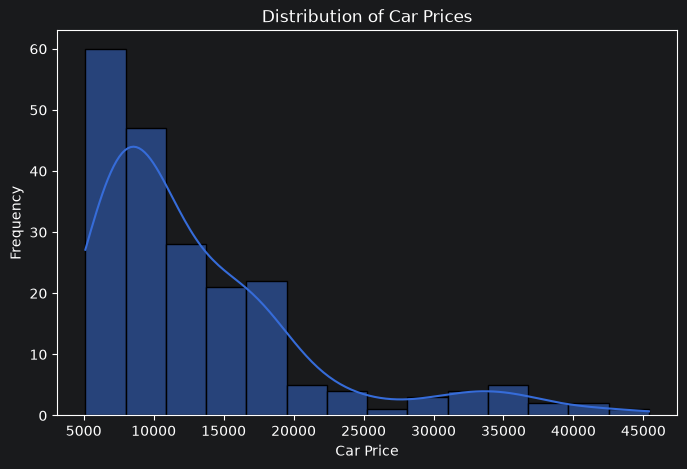

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.show()

Box plot of car prices

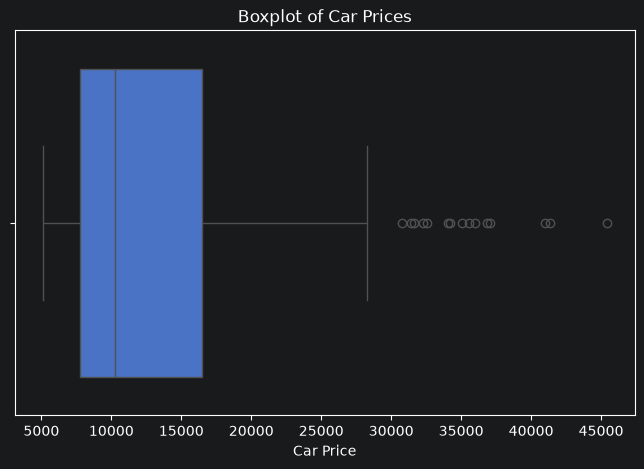

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['price'])

plt.title("Boxplot of Car Prices")
plt.xlabel("Car Price")

plt.show()

Correlation heatmap

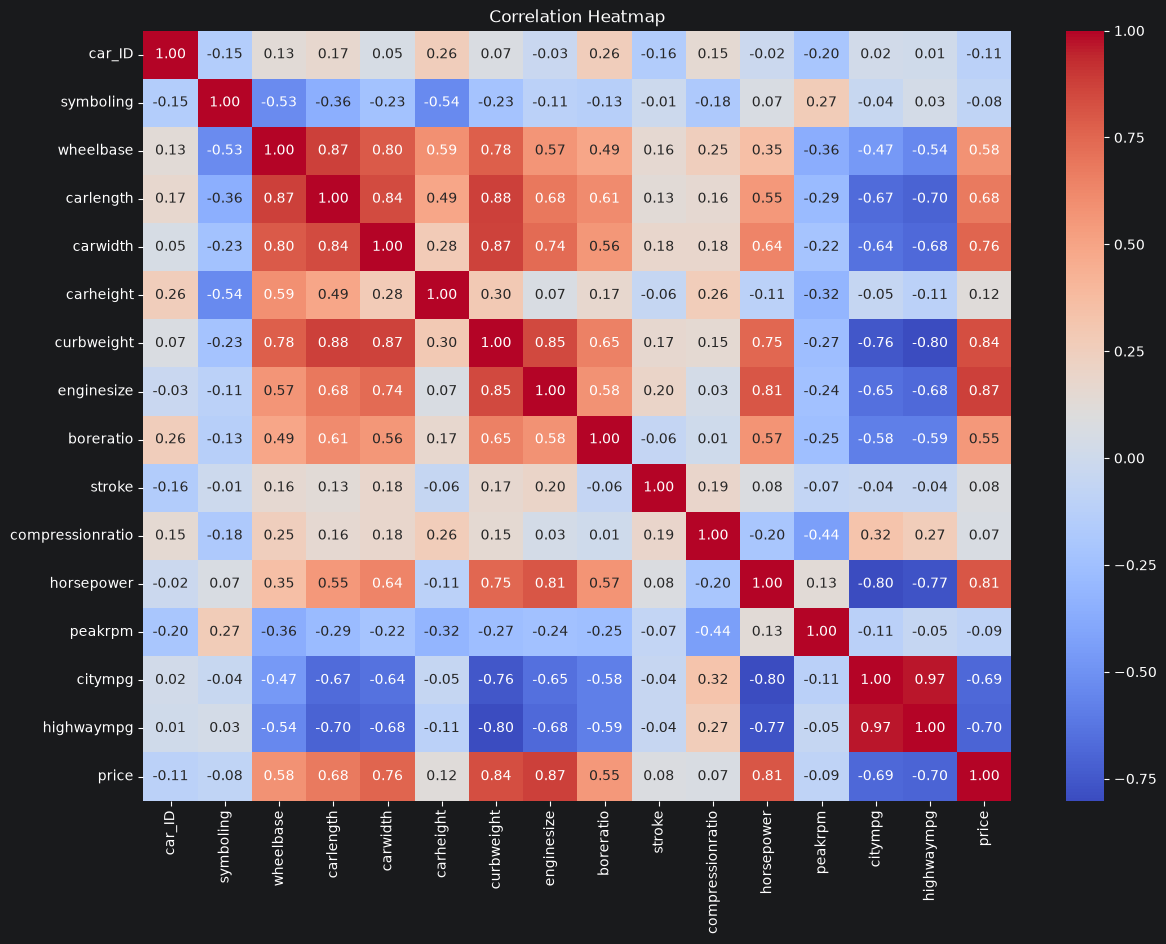

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

Relation between engine size and price

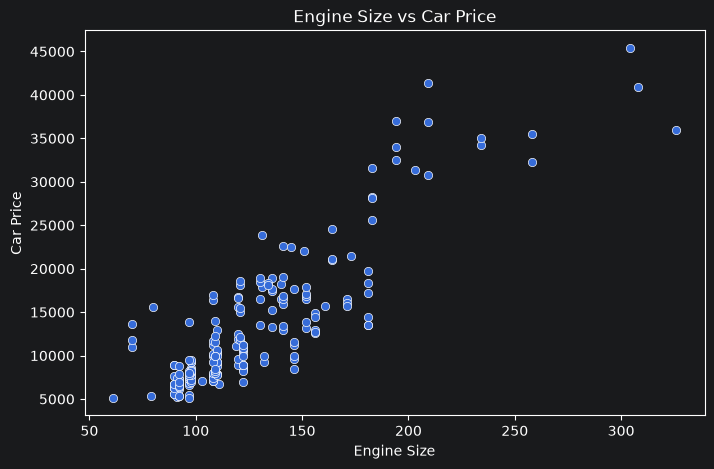

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='enginesize', y='price')

plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price")

plt.show()

DATA PREPROCESSING

In [13]:
# Remove car_ID because it is only an identifier

if 'car_ID' in df.columns:
    df = df.drop('car_ID', axis=1)


# Extract car manufacturer from CarName

if 'CarName' in df.columns:

    df['Brand'] = df['CarName'].str.split().str[0]

    df = df.drop('CarName', axis=1)


# Display updated dataset

df.head()

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,Brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


Separate independent and dependent variables

In [14]:
X = df.drop('price', axis=1)

y = df['price']

print("Independent Variables Shape:", X.shape)

print("Dependent Variable Shape:", y.shape)

Independent Variables Shape: (205, 24)
Dependent Variable Shape: (205,)


Identify numerical and categorical columns

In [16]:
numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']

Categorical Columns:
['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'Brand']


Split the dataset into training and testing data

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (164, 24)
Testing Data: (41, 24)


### Interpretation

The dataset was divided into 80% training data and 20% testing data.

The training dataset is used to train the machine learning models, while the testing dataset is used to evaluate their performance on unseen data.

Preprocessing pipeline

In [18]:
# Numerical preprocessing

numerical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler())

])


# Categorical preprocessing

categorical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('encoder', OneHotEncoder(handle_unknown='ignore'))

])


# Combine both preprocessing methods

preprocessor = ColumnTransformer(transformers=[

    ('num', numerical_transformer, numerical_columns),

    ('cat', categorical_transformer, categorical_columns)

])

### Interpretation

The unnecessary car_ID column was removed because it is only an identifier and does not provide meaningful information for price prediction.

The manufacturer name was extracted from the CarName column and stored as a new feature called Brand.

Numerical and categorical variables were identified. Missing-value handling, feature scaling and categorical encoding were incorporated into the preprocessing pipeline.

Implement the 5 regression algorithm

In [31]:
models = {

    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(random_state=42),

    'Random Forest': RandomForestRegressor(
        random_state=42,
        n_estimators=100
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    ),

    'Support Vector Regression': SVR()

}

Train all 5 models and make prediction

In [20]:
results = []

trained_models = {}

predictions = {}

for name, model in models.items():

    # Create pipeline

    pipeline = Pipeline(steps=[

        ('preprocessor', preprocessor),

        ('model', model)

    ])

    # Train the model

    pipeline.fit(X_train, y_train)

    # Predict car prices

    y_pred = pipeline.predict(X_test)

    # Evaluate model

    r2 = r2_score(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    mae = mean_absolute_error(y_test, y_pred)

    # Store results

    results.append({

        'Model': name,

        'R2 Score': r2,

        'MSE': mse,

        'MAE': mae

    })

    trained_models[name] = pipeline

    predictions[name] = y_pred

    print(name, "completed successfully!")

Linear Regression completed successfully!
Decision Tree completed successfully!
Random Forest completed successfully!
Gradient Boosting completed successfully!
Support Vector Regression completed successfully!


model evaluation and comparison

In [21]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

print(results_df)

                       Model  R2 Score           MSE          MAE
2              Random Forest  0.957621  3.345553e+06  1302.009667
3          Gradient Boosting  0.927507  5.722882e+06  1683.250835
0          Linear Regression  0.899880  7.903858e+06  1835.332222
1              Decision Tree  0.896224  8.192494e+06  1923.678854
4  Support Vector Regression -0.099789  8.682180e+07  5695.277764


    Visualise model comparison

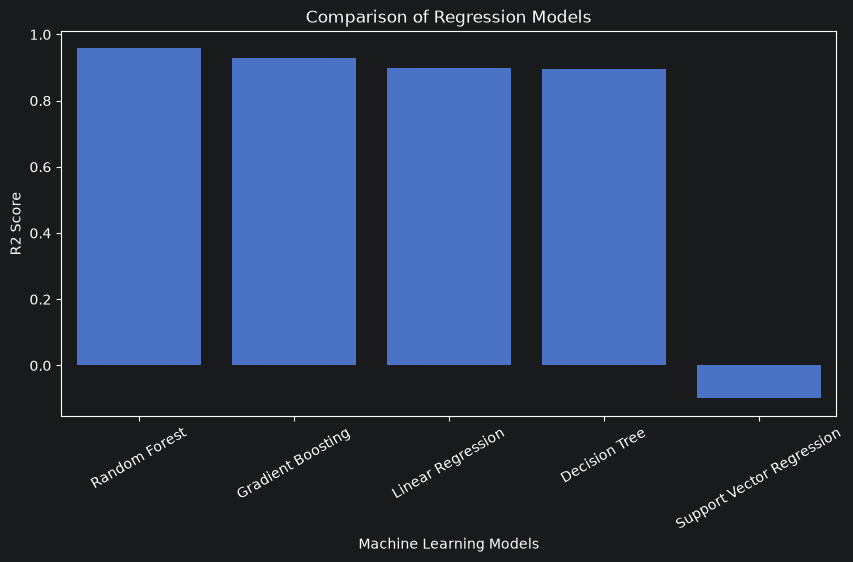

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Comparison of Regression Models")

plt.xlabel("Machine Learning Models")

plt.ylabel("R2 Score")

plt.xticks(rotation=30)

plt.show()

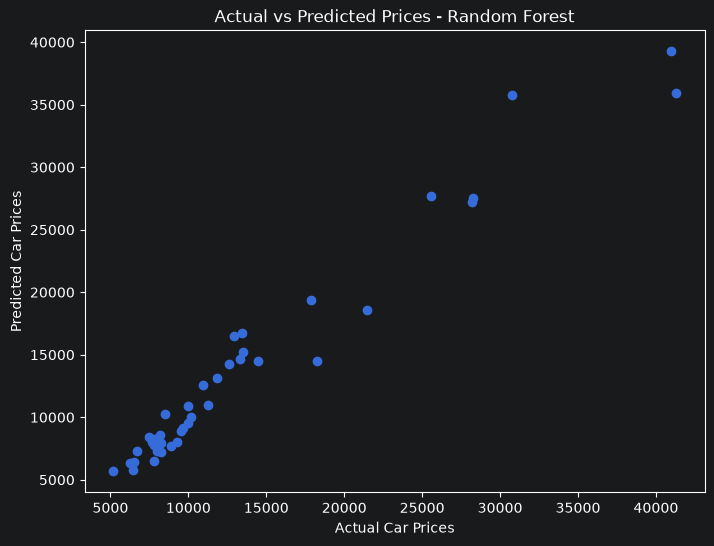

In [23]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions)

plt.xlabel("Actual Car Prices")

plt.ylabel("Predicted Car Prices")

plt.title(f"Actual vs Predicted Prices - {best_model_name}")

plt.show()

Feature importance analysis

In [24]:
from sklearn.inspection import permutation_importance

# Calculate feature importance

importance = permutation_importance(

    best_model,

    X_test,

    y_test,

    n_repeats=10,

    random_state=42,

    scoring='r2'

)

# Create feature importance dataframe

feature_importance = pd.DataFrame({

    'Feature': X.columns,

    'Importance': importance.importances_mean

})

# Sort features by importance

feature_importance = feature_importance.sort_values(

    by='Importance',

    ascending=False

)

print(feature_importance)

             Feature  Importance
14        enginesize    0.773602
11        curbweight    0.147699
22        highwaympg    0.007515
19        horsepower    0.005142
9           carwidth    0.002910
18  compressionratio    0.002826
21           citympg    0.002717
16         boreratio    0.002413
17            stroke    0.001989
8          carlength    0.001820
20           peakrpm    0.001754
23             Brand    0.001741
10         carheight    0.001151
13    cylindernumber    0.001052
4            carbody    0.000867
7          wheelbase    0.000696
5         drivewheel    0.000617
2         aspiration    0.000539
15        fuelsystem    0.000220
1           fueltype    0.000045
6     enginelocation    0.000000
0          symboling   -0.000153
12        enginetype   -0.000256
3         doornumber   -0.000309


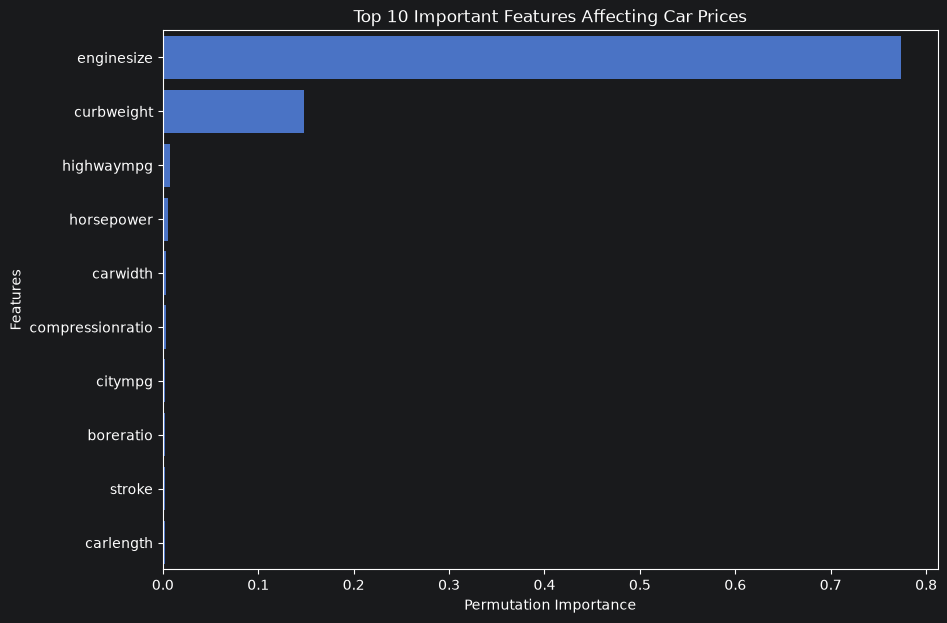

In [25]:
plt.figure(figsize=(10, 7))

sns.barplot(

    data=feature_importance.head(10),

    x='Importance',

    y='Feature'

)

plt.title("Top 10 Important Features Affecting Car Prices")

plt.xlabel("Permutation Importance")

plt.ylabel("Features")

plt.show()

Define hyperparameter values

In [26]:
param_grids = {

    'Linear Regression': {

        'model__fit_intercept': [True, False]

    },

    'Decision Tree': {

        'model__max_depth': [3, 5, 10, None],

        'model__min_samples_split': [2, 5, 10]

    },

    'Random Forest': {

        'model__n_estimators': [100, 200],

        'model__max_depth': [None, 5, 10],

        'model__min_samples_split': [2, 5]

    },

    'Gradient Boosting': {

        'model__n_estimators': [100, 200],

        'model__learning_rate': [0.01, 0.1, 0.2],

        'model__max_depth': [2, 3, 5]

    },

    'Support Vector Regression': {

        'model__C': [1, 10, 100],

        'model__epsilon': [0.1, 0.2, 0.5],

        'model__kernel': ['linear', 'rbf']

    }

}

GridsearchCV

In [27]:
best_model_pipeline = trained_models[best_model_name]

grid_search = GridSearchCV(

    estimator=best_model_pipeline,

    param_grid=param_grids[best_model_name],

    cv=5,

    scoring='r2',

    n_jobs=-1

)

# Train using different hyperparameter combinations

grid_search.fit(X_train, y_train)

print("Best Parameters:")

print(grid_search.best_params_)

print("\nBest Cross Validation R2 Score:")

print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best Cross Validation R2 Score:
0.8893929443073356


Evaluate tuned models

In [28]:
# Get the tuned model

tuned_model = grid_search.best_estimator_

# Make predictions

tuned_predictions = tuned_model.predict(X_test)

# Calculate evaluation metrics

tuned_r2 = r2_score(y_test, tuned_predictions)

tuned_mse = mean_squared_error(y_test, tuned_predictions)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)


print("Tuned Model:", best_model_name)

print("R2 Score:", tuned_r2)

print("MSE:", tuned_mse)

print("MAE:", tuned_mae)

Tuned Model: Random Forest
R2 Score: 0.959525249866283
MSE: 3195239.5196550842
MAE: 1251.487681752613


In [30]:
comparison = pd.DataFrame({

    'Metric': ['R2 Score', 'MSE', 'MAE'],

    'Before Tuning': [

        results_df.iloc[0]['R2 Score'],

        results_df.iloc[0]['MSE'],

        results_df.iloc[0]['MAE']

    ],

    'After Tuning': [

        tuned_r2,

        tuned_mse,

        tuned_mae

    ]

})

print(comparison)

     Metric  Before Tuning  After Tuning
0  R2 Score   9.576212e-01  9.595252e-01
1       MSE   3.345553e+06  3.195240e+06
2       MAE   1.302010e+03  1.251488e+03


### Interpretation

The model performance was compared before and after hyperparameter tuning using R-squared, Mean Squared Error (MSE) and Mean Absolute Error (MAE).

The R-squared score increased from **0.9576 to 0.9595**, indicating a slight improvement in the model's ability to explain variations in car prices.

The Mean Squared Error decreased from **3,345,553 to 3,195,240**, showing a reduction in squared prediction errors.

Similarly, the Mean Absolute Error decreased from **1,302.01 to 1,251.49**, indicating that the average absolute prediction error became smaller.

Overall, hyperparameter tuning improved the model's predictive performance. The tuned model performed better than the original model across all three evaluation metrics.